In [7]:
!pip install koreanize-matplotlib

In [8]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.tree import plot_tree
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

### 1. 파일 불러오기

In [10]:
url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"귀화예측_상위10컬럼_ID가중치포함.csv")
print(df["국적취득여부"].value_counts())        # 1 = 귀화 9460, 0 = 미귀화 8473

국적취득여부
1.0    9460
0.0    8473
Name: count, dtype: int64


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17933 entries, 0 to 17932
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   가구ID          17933 non-null  int64  
 1   가중치           17933 non-null  float64
 2   최초입국연도_년      17826 non-null  float64
 3   해외에서의교육년수     17002 non-null  float64
 4   혼인상태          17933 non-null  float64
 5   만나이           17933 non-null  float64
 6   출생시국적코드(외국)   17933 non-null  float64
 7   성별            17933 non-null  float64
 8   장애인복지카드유무     17933 non-null  float64
 9   최초입국여부        17933 non-null  float64
 10  이민귀화자와관계      17933 non-null  float64
 11  최종학력(학년이 아님)  17933 non-null  float64
 12  국적취득여부        17933 non-null  float64
dtypes: float64(12), int64(1)
memory usage: 1.8 MB


In [12]:
df.sample(10)

,가구ID,가중치,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
473,10405,8.781701,2003.0,9.0,2.0,54.0,122.0,1.0,2.0,1.0,1.0,1.0,1.0
16086,23978,5.840186,NaN,6.0,2.0,29.0,112.0,1.0,2.0,0.0,3.0,1.0,0.0
12671,20996,9.441760,2017.0,12.0,2.0,23.0,110.0,1.0,2.0,1.0,1.0,1.0,0.0
9431,18186,33.866140,2005.0,12.0,2.0,43.0,122.0,2.0,2.0,1.0,2.0,1.0,1.0
8512,17386,16.812027,2002.0,14.0,2.0,55.0,130.0,1.0,2.0,1.0,1.0,1.0,0.0
14888,22943,7.918494,2017.0,12.0,2.0,23.0,110.0,1.0,2.0,1.0,1.0,1.0,0.0
2544,12207,56.306616,2012.0,12.0,2.0,38.0,185.0,1.0,2.0,1.0,1.0,1.0,1.0
6527,15649,5.488065,1955.0,NaN,2.0,66.0,113.0,1.0,2.0,1.0,1.0,2.0,1.0
1573,11371,6.973083,2010.0,9.0,2.0,34.0,110.0,1.0,2.0,1.0,1.0,1.0,0.0
5272,14565,14.138426,2007.0,12.0,2.0,36.0,185.0,1.0,2.0,1.0,1.0,1.0,1.0


In [13]:
df.corr()

,가구ID,가중치,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
가구ID,1.000000,-0.015995,0.020213,0.025472,-0.022314,-0.022838,0.013746,-0.000198,0.004934,0.001753,0.003026,0.001109,-0.049169
가중치,-0.015995,1.000000,0.014933,-0.056172,0.042282,0.079233,-0.075503,0.053304,-0.014425,0.012747,0.031013,-0.013545,0.025328
최초입국연도_년,0.020213,0.014933,1.000000,0.039899,-0.153448,-0.557274,0.160698,-0.155659,0.051786,NaN,0.098663,-0.198970,-0.284011
해외에서의교육년수,0.025472,-0.056172,0.039899,1.000000,-0.016934,0.013284,0.107784,0.058658,0.046863,0.020309,-0.119707,0.012075,-0.183140
혼인상태,-0.022314,0.042282,-0.153448,-0.016934,1.000000,0.327971,-0.046349,-0.142449,0.007409,0.097951,-0.379420,-0.159492,0.140676
만나이,-0.022838,0.079233,-0.557274,0.013284,0.327971,1.000000,-0.142513,0.101055,-0.082435,0.076698,-0.287111,-0.097655,0.126919
출생시국적코드(외국),0.013746,-0.075503,0.160698,0.107784,-0.046349,-0.142513,1.000000,0.051461,0.009786,0.004655,-0.053253,-0.001970,-0.106821
성별,-0.000198,0.053304,-0.155659,0.058658,-0.142449,0.101055,0.051461,1.000000,-0.060675,-0.048817,0.298733,0.118494,-0.058333
장애인복지카드유무,0.004934,-0.014425,0.051786,0.046863,0.007409,-0.082435,0.009786,-0.060675,1.000000,-0.002262,-0.040837,-0.008096,-0.048844
최초입국여부,0.001753,0.012747,NaN,0.020309,0.097951,0.076698,0.004655,-0.048817,-0.002262,1.000000,-0.235926,-0.069270,0.028201


In [14]:
df.describe()

,가구ID,가중치,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
count,17933.000000,17933.000000,17826.000000,17002.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000
mean,17781.567947,20.114178,2007.520700,11.467298,2.072102,40.225060,153.538226,1.191379,1.987398,0.994033,1.202643,1.477946,0.527519
std,4497.397875,24.827095,8.346718,3.282803,0.559716,12.632633,61.840938,0.393398,0.111554,0.077015,0.528867,1.357445,0.499256
min,10000.000000,1.000000,1937.000000,1.000000,1.000000,0.000000,101.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000
25%,13904.000000,6.909612,2004.000000,9.000000,2.000000,32.000000,113.000000,1.000000,2.000000,1.000000,1.000000,1.000000,0.000000
50%,17783.000000,13.501138,2008.000000,12.000000,2.000000,38.000000,130.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000
75%,21677.000000,25.174569,2013.000000,14.000000,2.000000,48.000000,185.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000
max,25577.000000,1893.613316,2021.000000,22.000000,4.000000,95.000000,999.000000,2.000000,2.000000,1.000000,3.000000,7.000000,1.000000


In [15]:
df = df.fillna(df.median())
df.corr()

,가구ID,가중치,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
가구ID,1.000000,-0.015995,0.020139,0.025041,-0.022314,-0.022838,0.013746,-0.000198,0.004934,0.001753,0.003026,0.001109,-0.049169
가중치,-0.015995,1.000000,0.014856,-0.046768,0.042282,0.079233,-0.075503,0.053304,-0.014425,0.012747,0.031013,-0.013545,0.025328
최초입국연도_년,0.020139,0.014856,1.000000,0.023439,-0.152720,-0.551960,0.159782,-0.154514,0.051681,-0.004436,0.096759,-0.197012,-0.283250
해외에서의교육년수,0.025041,-0.046768,0.023439,1.000000,-0.024731,0.004571,0.103825,0.061350,0.043269,0.004745,-0.085501,0.023706,-0.175416
혼인상태,-0.022314,0.042282,-0.152720,-0.024731,1.000000,0.327971,-0.046349,-0.142449,0.007409,0.097951,-0.379420,-0.159492,0.140676
만나이,-0.022838,0.079233,-0.551960,0.004571,0.327971,1.000000,-0.142513,0.101055,-0.082435,0.076698,-0.287111,-0.097655,0.126919
출생시국적코드(외국),0.013746,-0.075503,0.159782,0.103825,-0.046349,-0.142513,1.000000,0.051461,0.009786,0.004655,-0.053253,-0.001970,-0.106821
성별,-0.000198,0.053304,-0.154514,0.061350,-0.142449,0.101055,0.051461,1.000000,-0.060675,-0.048817,0.298733,0.118494,-0.058333
장애인복지카드유무,0.004934,-0.014425,0.051681,0.043269,0.007409,-0.082435,0.009786,-0.060675,1.000000,-0.002262,-0.040837,-0.008096,-0.048844
최초입국여부,0.001753,0.012747,-0.004436,0.004745,0.097951,0.076698,0.004655,-0.048817,-0.002262,1.000000,-0.235926,-0.069270,0.028201


In [16]:
df["체류기간"] = 2021 - df["최초입국연도_년"]
df = df.drop(columns=["최초입국연도_년"])

In [17]:
코드컬럼 = ["혼인상태", "성별", "출생시국적코드(외국)", "장애인복지카드유무",
          "최초입국여부"]
df = pd.get_dummies(df, columns=코드컬럼, drop_first=True)

In [18]:
X = df.drop(columns=["국적취득여부","최종학력(학년이 아님)","이민귀화자와관계",'가구ID',"가중치"])
y = df["국적취득여부"]

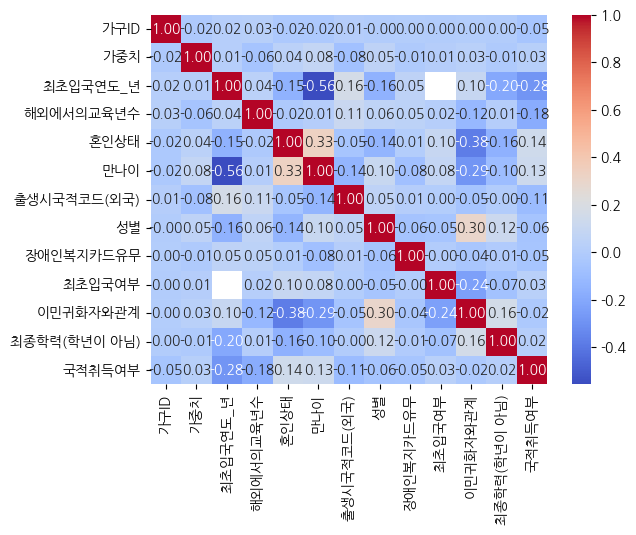

In [19]:
one = pd.read_csv(url+"귀화예측_상위10컬럼_ID가중치포함.csv")
sns.heatmap(one.corr(),
            annot=True,
            fmt=".2f",
            cmap="coolwarm")
plt.show()

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [21]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [22]:
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=200)

In [23]:
pred = model.predict(X_test_s)                     # 0 또는 1로 예측
prob = model.predict_proba(X_test_s)[:, 1]
print(pred)
print(prob)
print(round(accuracy_score(y_test, pred),2)) # 정확도 평균

[1. 1. 1. ... 0. 1. 1.]
[1.         0.79068254 0.72516732 ... 0.01469638 0.9999955  0.7158703 ]
0.63


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


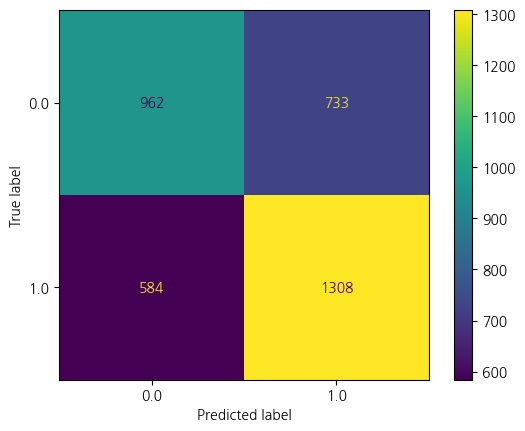

In [24]:
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

#**결정트리**

In [25]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier(max_depth=5,random_state=42)
dt.fit(X_train_s,y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [26]:
print(dt.score(X_train,y_train))

0.5283702774292486


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [27]:
print(dt.score(X_test,y_test))

0.5277390577083915


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [28]:

pr = dt.predict(X_test_s)
cm = confusion_matrix(y_test,pr)
print(cm)

[[1225  470]
 [ 422 1470]]


In [29]:
pr = dt.predict(X_train_s)
cm = confusion_matrix(y_train,pr)
print(cm)

[[4898 1880]
 [1603 5965]]


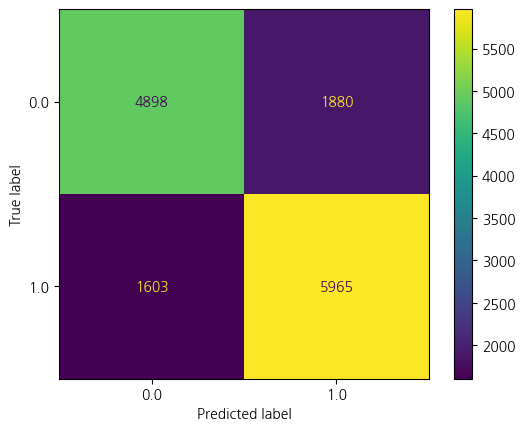

In [30]:
ConfusionMatrixDisplay.from_predictions(y_train, pr)
plt.show()

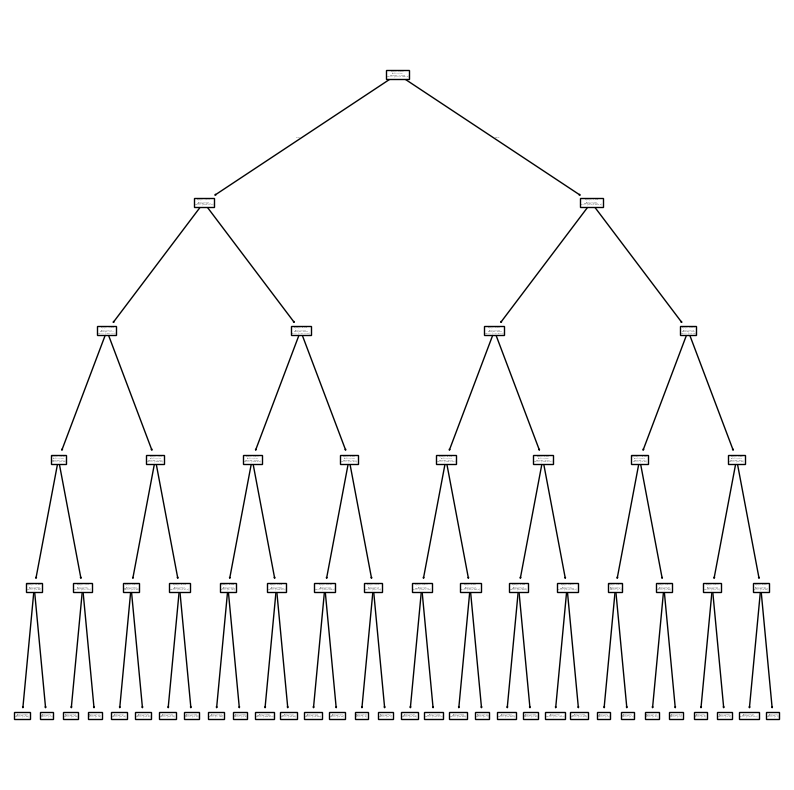

In [31]:
plt.figure(figsize=(10,10))
plot_tree(dt,max_depth=5)
plt.show()

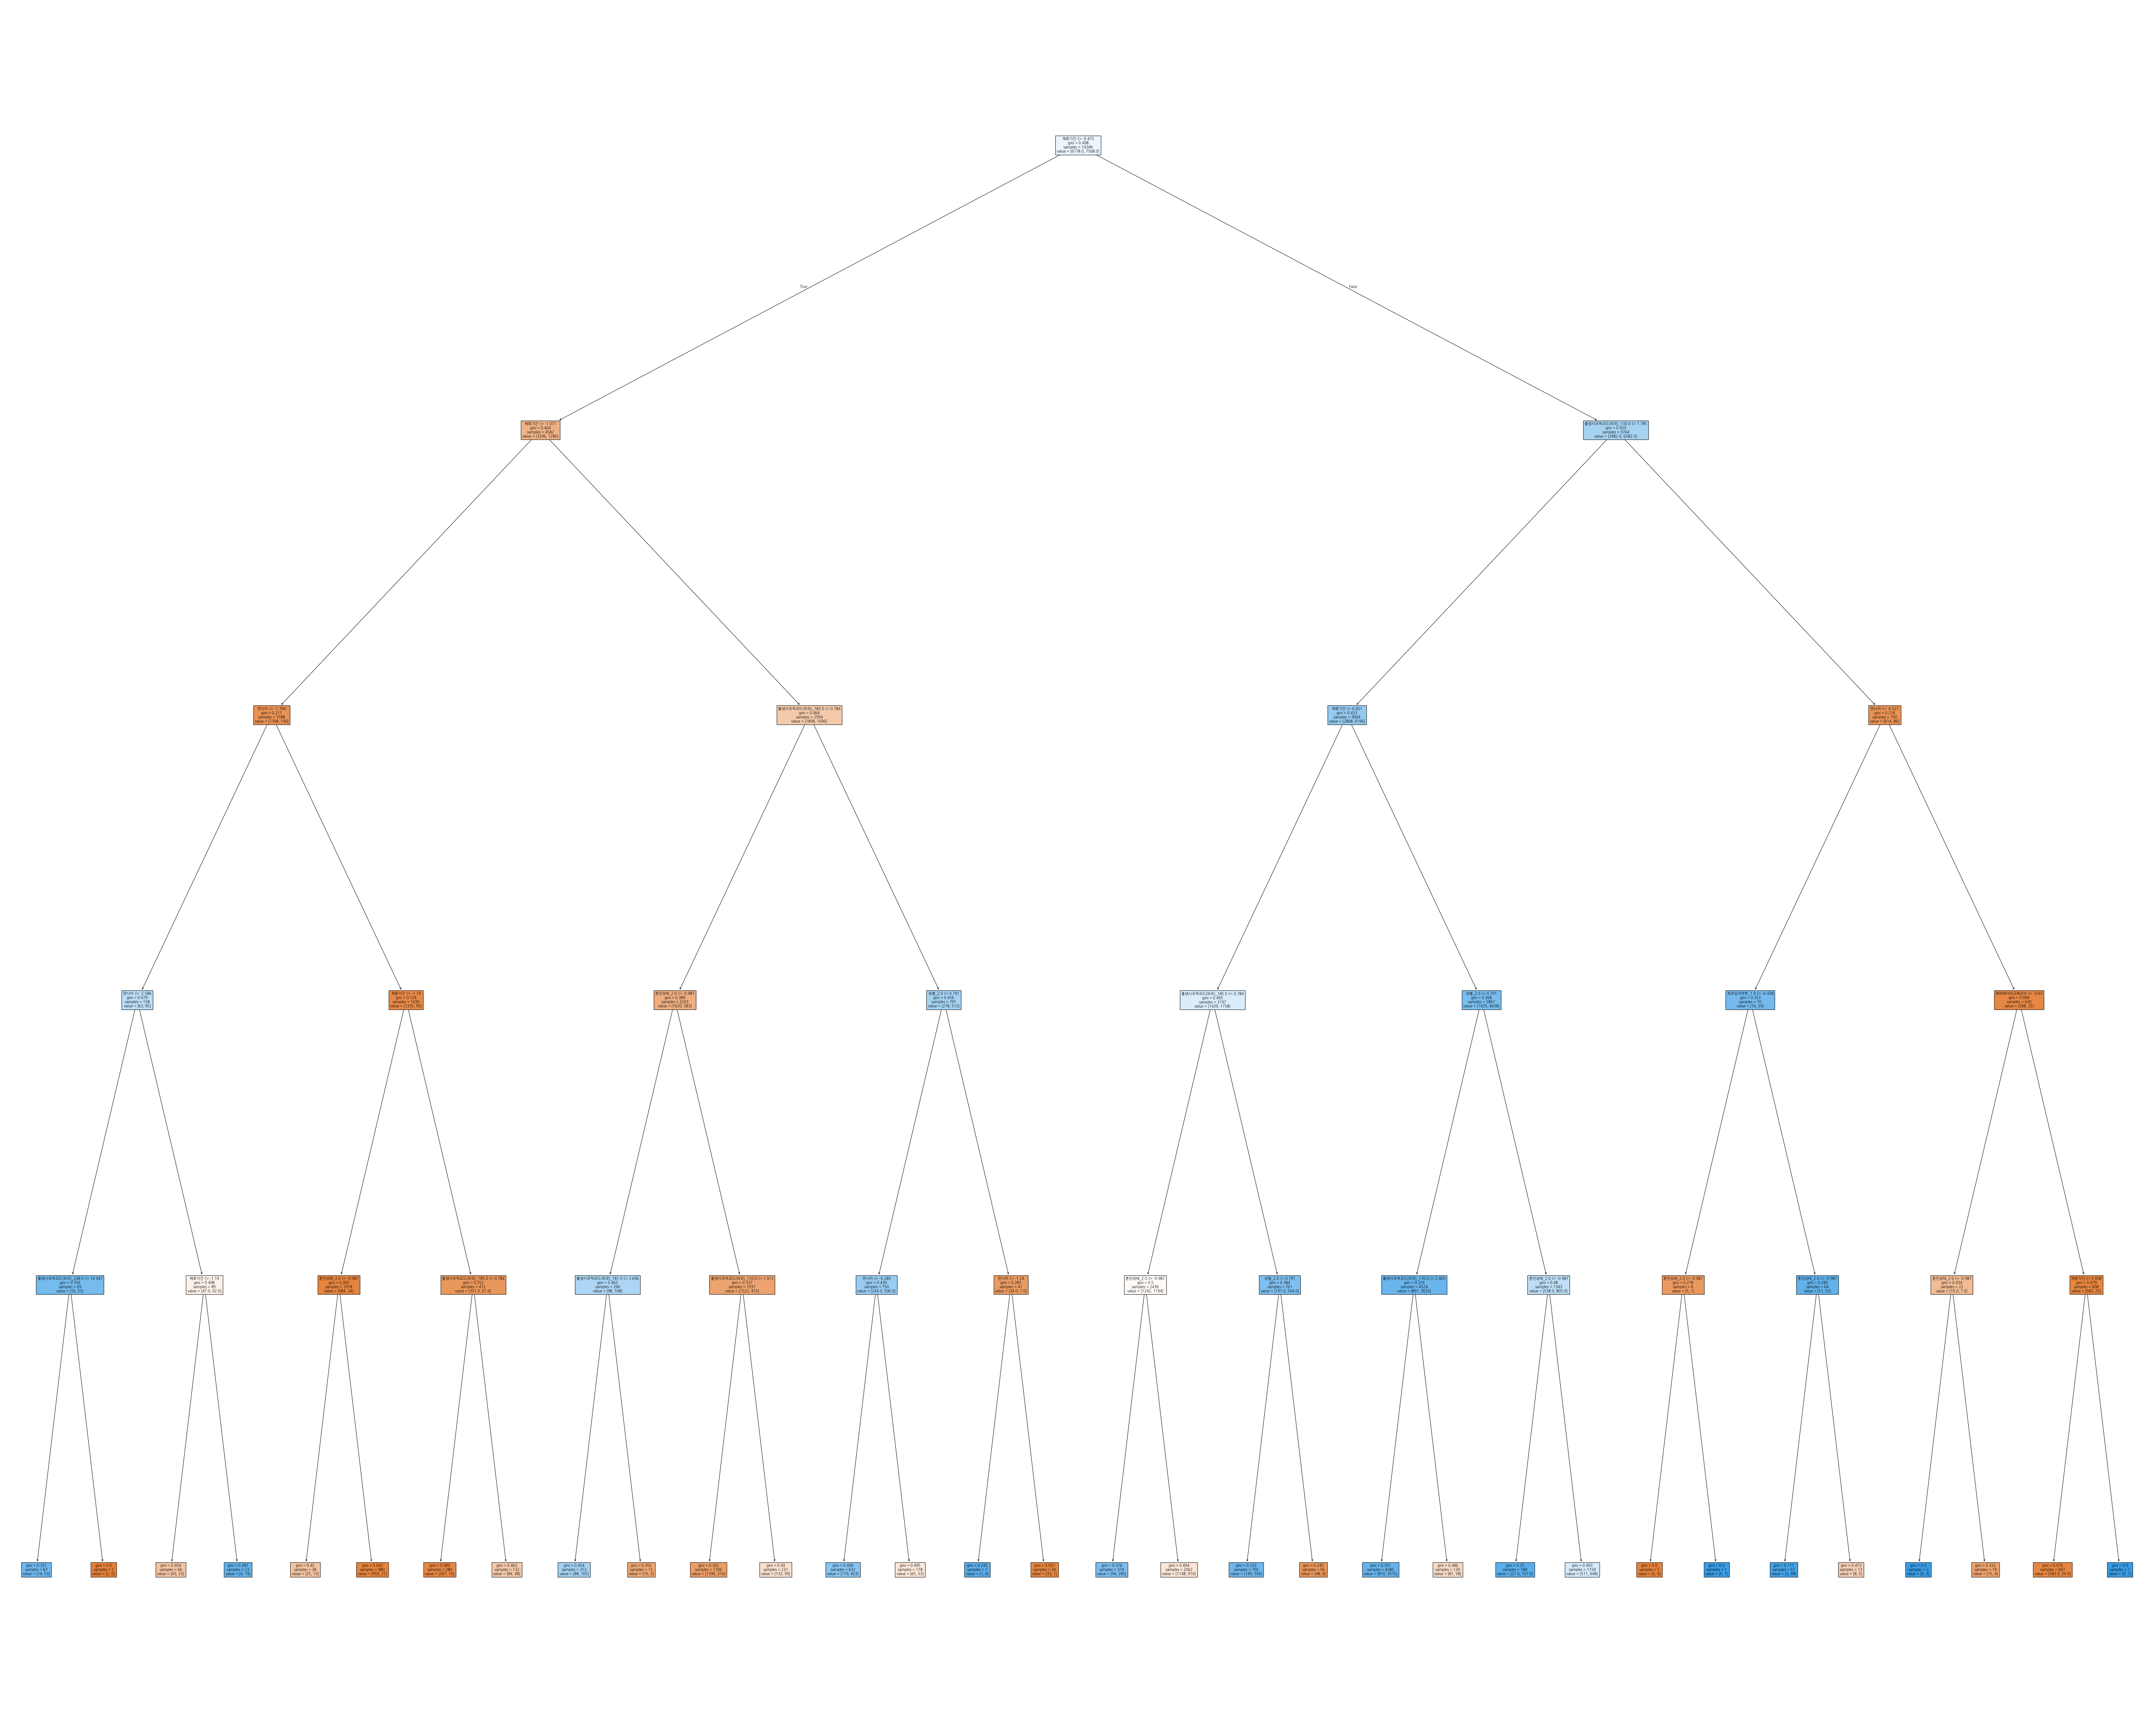

In [32]:
plt.figure(figsize=(100,80))
plot_tree(
    dt, max_depth=5,
    filled=True,
    feature_names=list(X.columns)
)
plt.show()

In [33]:
print(dt.feature_importances_)

[0.00135534 0.07311609 0.47420965 0.07768703 0.         0.
 0.06191605 0.         0.         0.01001852 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.16990147 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.01774851 0.         0.00182594 0.10921492 0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.00101056 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         

#**교차검증**

In [34]:
sub_input, val_input, sub_target, val_target = train_test_split(
    X_train_s, y_train, test_size=0.2, random_state=42)
print(sub_input.shape, val_input.shape, sub_target.shape, val_target.shape)

(11476, 117) (2870, 117) (11476,) (2870,)


In [35]:
cross=DecisionTreeClassifier(max_depth=5,random_state=42)
cross.fit(sub_input,sub_target)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [36]:
print(dt.score(sub_input,sub_target))

0.7574939003136981


In [37]:
print(dt.score(val_input,val_target))

0.7560975609756098


In [38]:
from sklearn.model_selection import cross_validate

scs =cross_validate(cross,X_train_s,y_train)
print(scs)

{'fit_time': array([0.06398082, 0.07977319, 0.07545781, 0.12476563, 0.09554601]), 'score_time': array([0.00353622, 0.00340462, 0.00759244, 0.00724387, 0.00366354]), 'test_score': array([0.76480836, 0.74346462, 0.74729871, 0.75287557, 0.74834437])}


In [39]:
import numpy as np

print(np.mean(scs['test_score']))

0.7513583263602392


In [40]:
from sklearn.model_selection import StratifiedKFold

scs=cross_validate(cross,X_train_s,y_train, cv=StratifiedKFold())
print(np.mean(scs['test_score']))

0.7513583263602392


#**5-Fold 교차 검증**

In [41]:
splitter = StratifiedKFold(shuffle=True, random_state=42)
scs=cross_validate(cross,X_train_s,y_train,cv=splitter)
print(np.mean(scs['test_score']))

0.7532409767756494


In [42]:
splitter = StratifiedKFold(n_splits=45,shuffle=True, random_state=42)
scs=cross_validate(cross,X_train_s,y_train,cv=splitter)
print(np.mean(scs['test_score']))

0.7548383422163514


#**GridSearchCV**

In [43]:
from sklearn.model_selection import GridSearchCV

params = {
    "max_depth": [3, 5, 7, 9, 11, 13, 15],                 # 나무 깊이
    "min_samples_leaf": [1, 10, 20, 50, 100],               # 맨 끝 칸에 최소 몇 명
    "min_impurity_decrease": [0.0, 0.0001, 0.0005, 0.001],  # 가지를 나눌 최소 이득
}

In [44]:
gs = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
)
gs.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [3, 5, 7, 9, 11, 13, 15],
                         'min_impurity_decrease': [0.0, 0.0001, 0.0005, 0.001],
                         'min_samples_leaf': [1, 10, 20, 50, 100]})

In [45]:
print(gs.best_params_)
print(f"교차검증 정확도:{round(gs.best_score_, 2)}")

{'max_depth': 11, 'min_impurity_decrease': 0.0005, 'min_samples_leaf': 1}
교차검증 정확도:0.77


In [46]:
gs_model = gs.best_estimator_
print(gs_model.score(X_train_s, y_train))

0.5275338073330545


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [47]:
print(gs_model.score(X_train, y_train))

0.7793113062874669


In [48]:
print(gs_model.score(X_test_s, y_test))

0.5274602732088096


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [49]:
print(gs_model.score(X_test, y_test))

0.7741845553387232


In [50]:
print(gs.cv_results_['mean_test_score'])

[0.71908458 0.71908458 0.71908458 0.71894516 0.71657509 0.71908458
 0.71908458 0.71908458 0.71894516 0.71657509 0.71908458 0.71908458
 0.71908458 0.71894516 0.71657509 0.71908458 0.71908458 0.71908458
 0.71894516 0.71657509 0.75324098 0.75240447 0.75261343 0.74871015
 0.74466695 0.75324098 0.75240447 0.75261343 0.74871015 0.74466695
 0.75101021 0.7508011  0.75170732 0.74933747 0.74410926 0.74996465
 0.74996465 0.74996465 0.74647933 0.74313331 0.76613687 0.76571849
 0.76481196 0.76425461 0.75742323 0.76676425 0.76578817 0.76536964
 0.7635576  0.75791121 0.76725198 0.76711258 0.76613665 0.76425459
 0.75735352 0.76279059 0.76279059 0.76230266 0.76049021 0.75477413
 0.76871576 0.7674607  0.76920322 0.76815827 0.75867793 0.77080703
 0.7687852  0.77017929 0.76753097 0.75930532 0.77143421 0.77052802
 0.76850655 0.76599733 0.75832918 0.76251184 0.76251184 0.76202392
 0.76083886 0.75477413 0.7669733  0.76711224 0.76983079 0.76550948
 0.75930515 0.77157419 0.76767029 0.76983118 0.76453372 0.7589

#**RandomizedSearchCV**

In [51]:
params = {
    "max_depth": randint(3, 20),                       # 3 ~ 19 정수
    "min_samples_split": randint(2, 100),              # 2 ~ 99 정수
    "min_samples_leaf": randint(1, 50),                # 1 ~ 49 정수
    "min_impurity_decrease": uniform(0.0001, 0.001),}

In [52]:
ugen = uniform(0, 1)
ugen.rvs(10)

array([0.98017032, 0.49262598, 0.94754571, 0.99161132, 0.34932723,
       0.71609625, 0.42288312, 0.48959213, 0.82278615, 0.01941971])

In [53]:
from sklearn.model_selection import RandomizedSearchCV

rs = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), params,
                        n_iter=50, cv=5, random_state=42)
rs.fit(X_train_s, y_train)

RandomizedSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
                   n_iter=50,
                   param_distributions={'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a5d70933380>,
                                        'min_impurity_decrease': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a5d709338c0>,
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a5d702cf110>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a5d702cf750>},
                   random_state=42)

In [54]:
print(rs.best_params_)

{'max_depth': 14, 'min_impurity_decrease': np.float64(0.0003517822958253642), 'min_samples_leaf': 2, 'min_samples_split': 4}


In [55]:
print(np.max(rs.cv_results_['mean_test_score']))

0.773386057616987


In [56]:
random = rs.best_estimator_

print(random.score(X_test, y_test))

0.5282966267075551


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [57]:
print(random.score(X_train, y_train))

0.5433570333193921


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


#KNN


In [58]:
from sklearn.neighbors import KNeighborsClassifier

kn= KNeighborsClassifier()
kn.fit(X_train ,y_train)

print(kn.score(X_train_s,y_train))
print(kn.score(X_test_s,y_test))
#0.835 , 0.741 로 과적합


0.8049630559040848
0.7175913019236131


In [62]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid = GridSearchCV(
    pipe,
    {"kneighborsclassifier__n_neighbors": [5, 15, 31, 51, 101],
     "kneighborsclassifier__weights": ["uniform", "distance"]},
    cv=5, scoring="roc_auc")
grid.fit(X_train_s, y_train)

print(grid.best_params_)
from sklearn.metrics import classification_report
print(classification_report(y_test, grid.predict(X_test_s)))

print(grid.score(X_train_s,y_train))
print(grid.score(X_test_s,y_test))
#훈련데이터점수 증가량보다 테스트데이터 점수증가량이 높아 과적합이 완화됨

{'kneighborsclassifier__n_neighbors': 31, 'kneighborsclassifier__weights': 'uniform'}
              precision    recall  f1-score   support

         0.0       0.78      0.68      0.73      1695
         1.0       0.74      0.82      0.78      1892

    accuracy                           0.76      3587
   macro avg       0.76      0.75      0.75      3587
weighted avg       0.76      0.76      0.76      3587

0.866794783458734
0.8409499398180197
